In [1]:
pip install lime tensorflow keras matplotlib numpy pillow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=27a13fc0d0a942baab7b8b4f0cecf496d985f49b4415ccbdb2f46afe03468d0a
  Stored in directory: /root/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime


In [2]:
pip install tensorflow keras shap matplotlib numpy pillow


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: 0, Grade 0: A healthy knee joint with no symptoms of osteoarthritis. with confidence level of 0.97


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [02:48, 168.95s/it]              


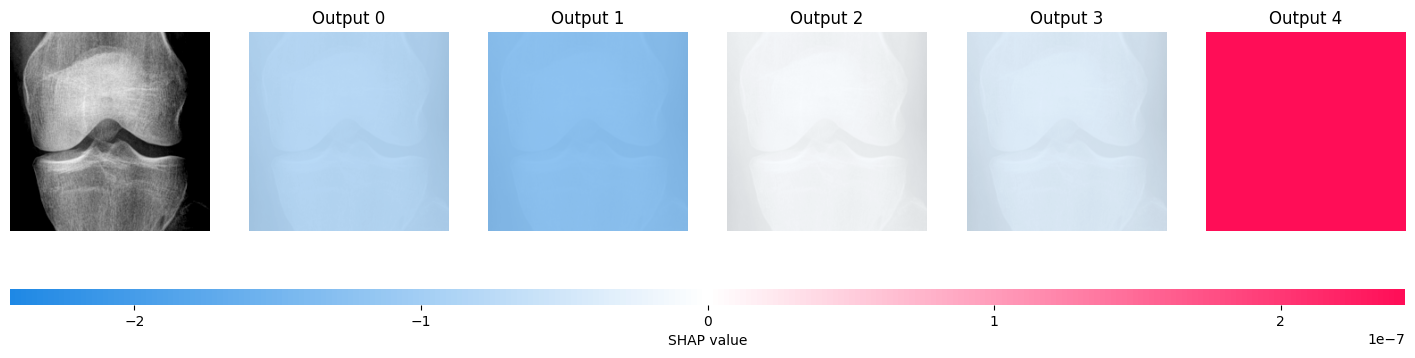

<Figure size 640x480 with 0 Axes>

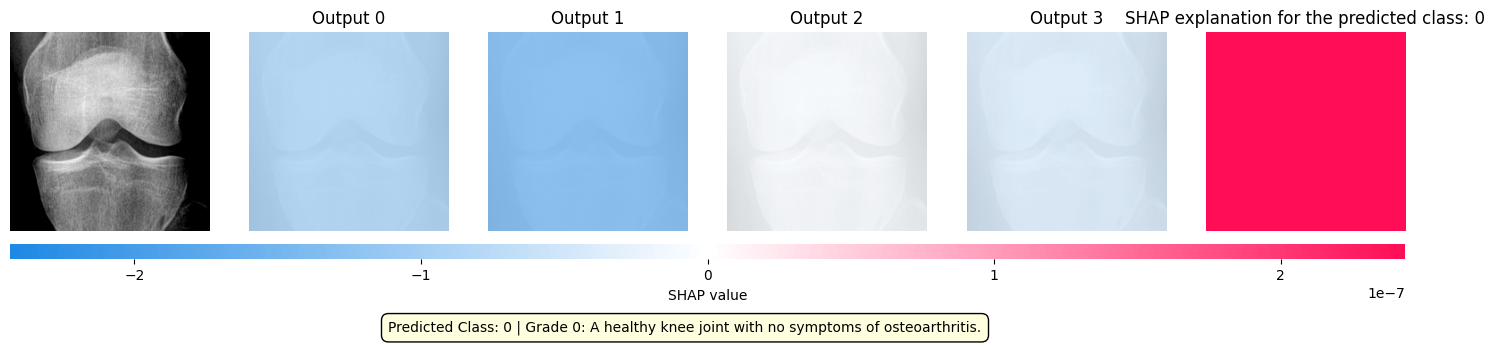

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import shap
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-0.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using SHAP
# Create a masker that masks out the input image pixels
masker = shap.maskers.Image("inpaint_telea", input_img.shape)

# Create the SHAP explainer
explainer = shap.Explainer(model, masker=masker)

# Get the SHAP values
shap_values = explainer(input_img_preprocessed)

# Display the explanation
shap.image_plot(shap_values, input_img_preprocessed)

# Visualize the SHAP values with proper labels
plt.figure()
shap.image_plot(shap_values, input_img_preprocessed, show=False)
plt.title(f"SHAP explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("SHAP Value")
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: 1, Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping. with confidence level of 0.65


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [02:49, 169.08s/it]              


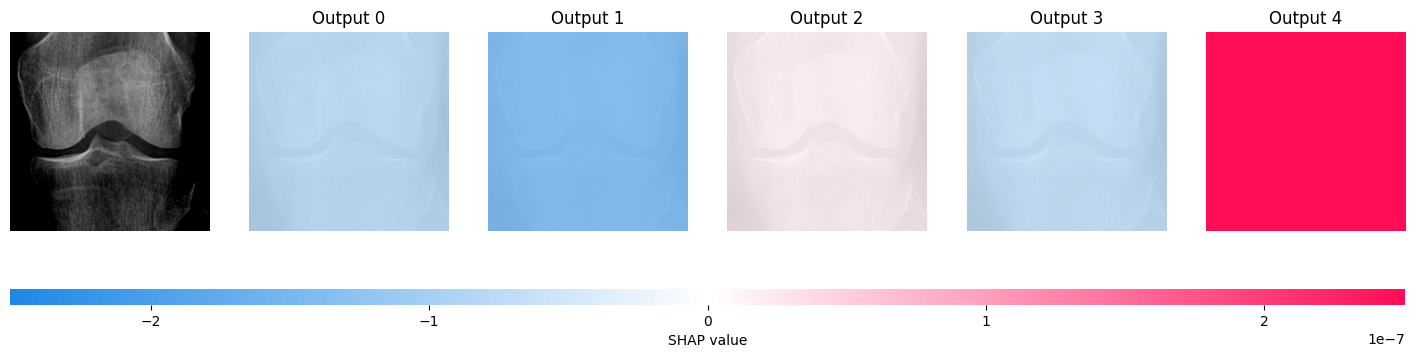

<Figure size 640x480 with 0 Axes>

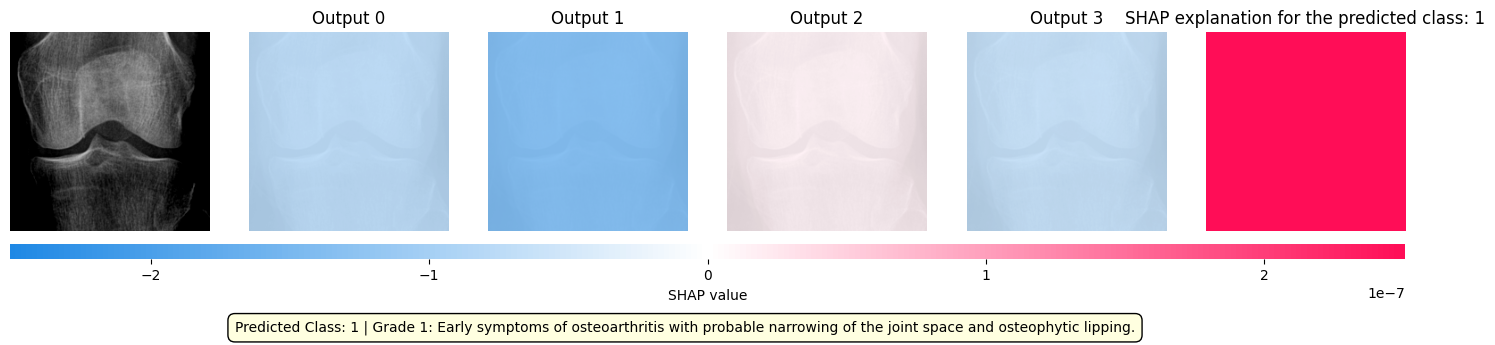

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import shap
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-1.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using SHAP
# Create a masker that masks out the input image pixels
masker = shap.maskers.Image("inpaint_telea", input_img.shape)

# Create the SHAP explainer
explainer = shap.Explainer(model, masker=masker)

# Get the SHAP values
shap_values = explainer(input_img_preprocessed)

# Display the explanation
shap.image_plot(shap_values, input_img_preprocessed)

# Visualize the SHAP values with proper labels
plt.figure()
shap.image_plot(shap_values, input_img_preprocessed, show=False)
plt.title(f"SHAP explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("SHAP Value")
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Class: 2, Grade 2: Clear presence of osteophytes and potential joint space constriction. with confidence level of 0.98


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [02:42, 162.11s/it]              


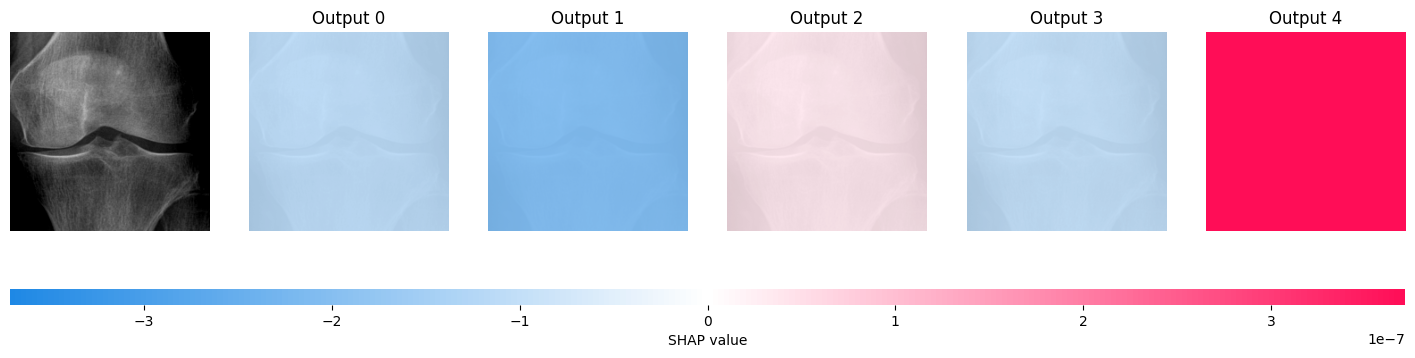

<Figure size 640x480 with 0 Axes>

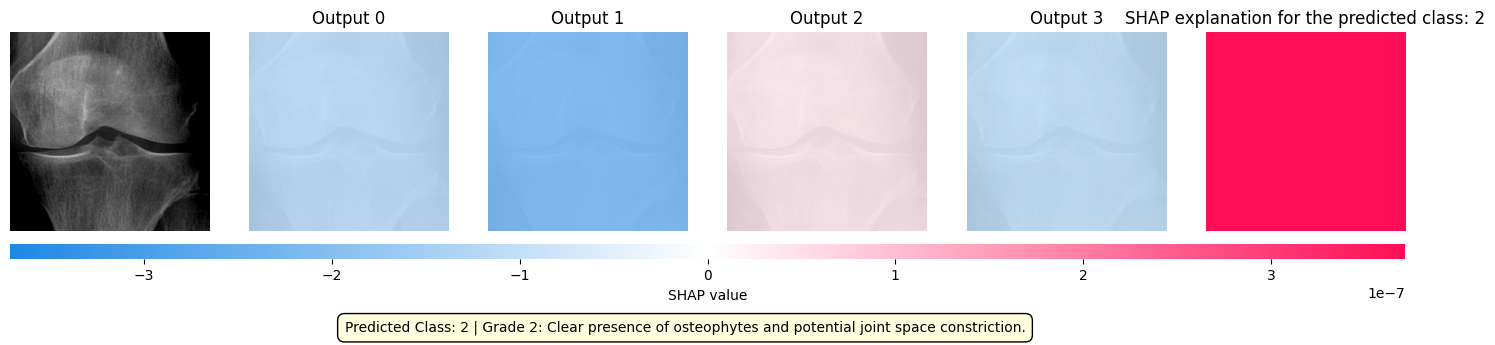

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import shap
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-2.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using SHAP
# Create a masker that masks out the input image pixels
masker = shap.maskers.Image("inpaint_telea", input_img.shape)

# Create the SHAP explainer
explainer = shap.Explainer(model, masker=masker)

# Get the SHAP values
shap_values = explainer(input_img_preprocessed)

# Display the explanation
shap.image_plot(shap_values, input_img_preprocessed)

# Visualize the SHAP values with proper labels
plt.figure()
shap.image_plot(shap_values, input_img_preprocessed, show=False)
plt.title(f"SHAP explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("SHAP Value")
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: 3, Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis. with confidence level of 0.97


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [02:48, 168.22s/it]              


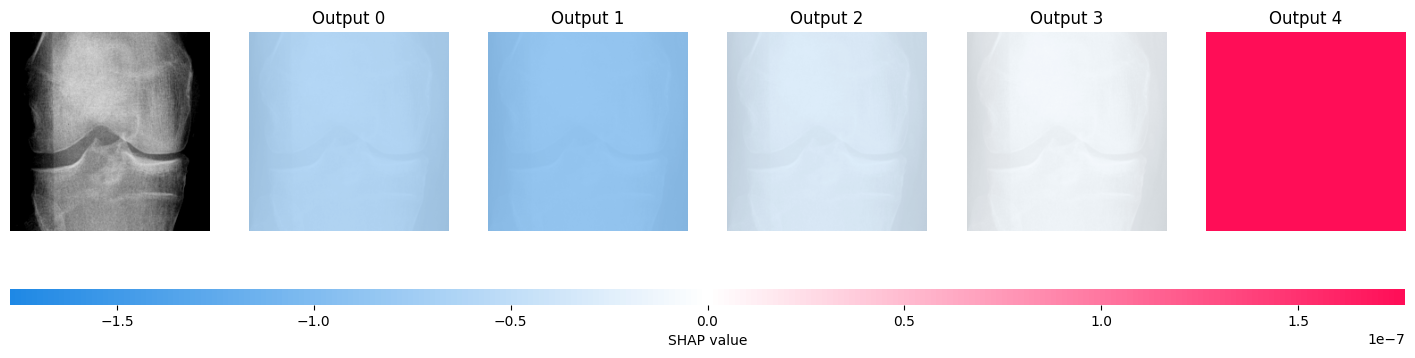

<Figure size 640x480 with 0 Axes>

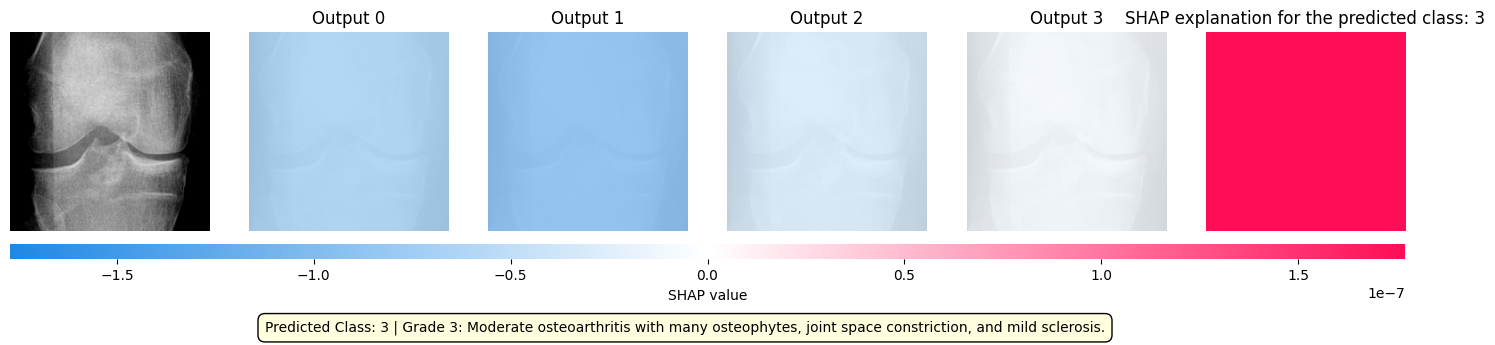

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import shap
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-3.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using SHAP
# Create a masker that masks out the input image pixels
masker = shap.maskers.Image("inpaint_telea", input_img.shape)

# Create the SHAP explainer
explainer = shap.Explainer(model, masker=masker)

# Get the SHAP values
shap_values = explainer(input_img_preprocessed)

# Display the explanation
shap.image_plot(shap_values, input_img_preprocessed)

# Visualize the SHAP values with proper labels
plt.figure()
shap.image_plot(shap_values, input_img_preprocessed, show=False)
plt.title(f"SHAP explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("SHAP Value")
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Class: 4, Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis. with confidence level of 0.97


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [02:36, 156.74s/it]              


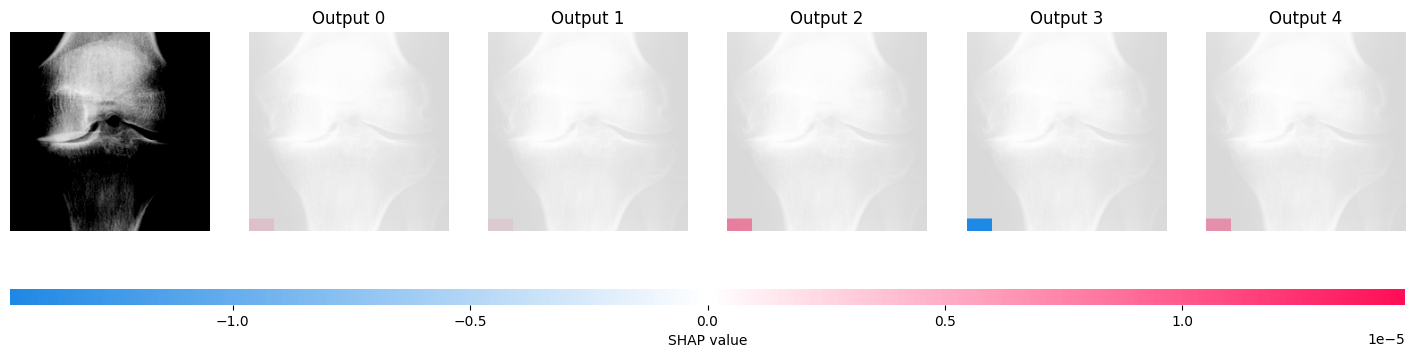

<Figure size 640x480 with 0 Axes>

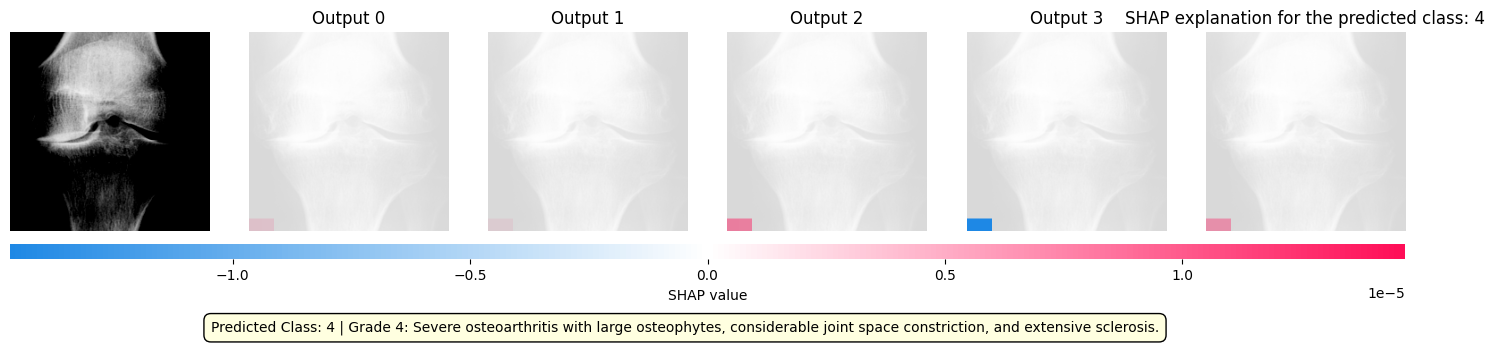

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import shap
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-4.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using SHAP
# Create a masker that masks out the input image pixels
masker = shap.maskers.Image("inpaint_telea", input_img.shape)

# Create the SHAP explainer
explainer = shap.Explainer(model, masker=masker)

# Get the SHAP values
shap_values = explainer(input_img_preprocessed)

# Display the explanation
shap.image_plot(shap_values, input_img_preprocessed)

# Visualize the SHAP values with proper labels
plt.figure()
shap.image_plot(shap_values, input_img_preprocessed, show=False)
plt.title(f"SHAP explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("SHAP Value")
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: 1, Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping. with confidence level of 0.65


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

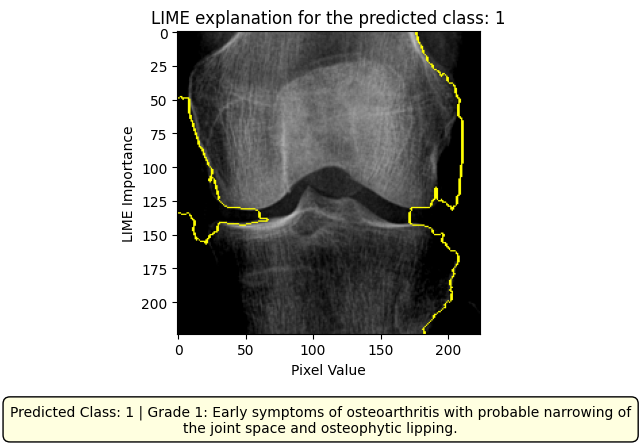

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input
from skimage.segmentation import mark_boundaries

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-1.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using LIME
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(input_img, model.predict, top_labels=5, hide_color=0, num_samples=1000)

# Get the LIME explanation for the predicted class
lime_image, mask = explanation.get_image_and_mask(predicted_class, positive_only=True, num_features=5, hide_rest=False)

# Display the LIME explanation
plt.figure()
plt.imshow(mark_boundaries(lime_image, mask))
plt.title(f"LIME explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("LIME Importance")

# Adjust layout to leave space for text
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Class: 0, Grade 0: A healthy knee joint with no symptoms of osteoarthritis. with confidence level of 0.98


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

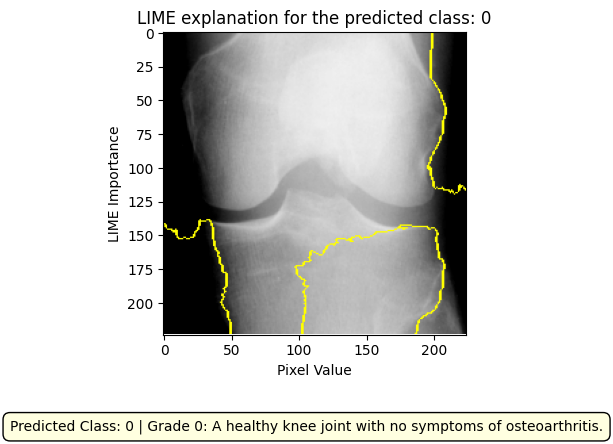

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input
from skimage.segmentation import mark_boundaries

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-0.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using LIME
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(input_img, model.predict, top_labels=5, hide_color=0, num_samples=1000)

# Get the LIME explanation for the predicted class
lime_image, mask = explanation.get_image_and_mask(predicted_class, positive_only=True, num_features=5, hide_rest=False)

# Display the LIME explanation
plt.figure()
plt.imshow(mark_boundaries(lime_image, mask))
plt.title(f"LIME explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("LIME Importance")

# Adjust layout to leave space for text
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: 2, Grade 2: Clear presence of osteophytes and potential joint space constriction. with confidence level of 0.98


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

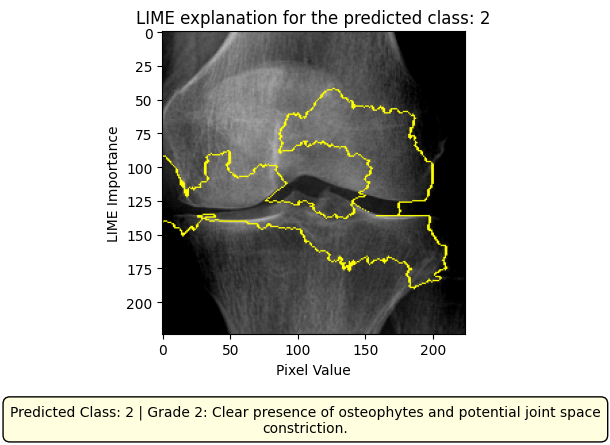

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input
from skimage.segmentation import mark_boundaries

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-2.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using LIME
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(input_img, model.predict, top_labels=5, hide_color=0, num_samples=1000)

# Get the LIME explanation for the predicted class
lime_image, mask = explanation.get_image_and_mask(predicted_class, positive_only=True, num_features=5, hide_rest=False)

# Display the LIME explanation
plt.figure()
plt.imshow(mark_boundaries(lime_image, mask))
plt.title(f"LIME explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("LIME Importance")

# Adjust layout to leave space for text
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: 3, Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis. with confidence level of 0.97


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

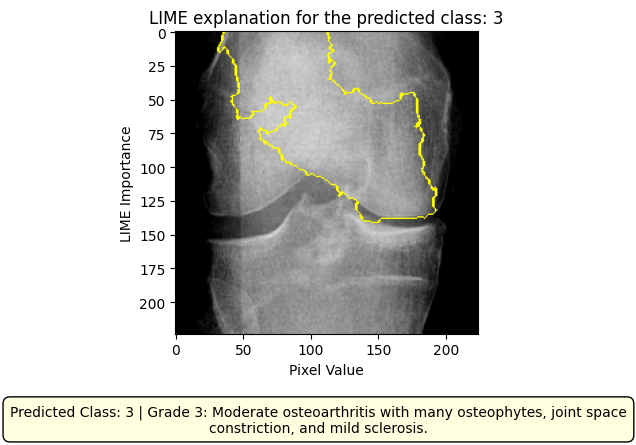

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input
from skimage.segmentation import mark_boundaries

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-3.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using LIME
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(input_img, model.predict, top_labels=5, hide_color=0, num_samples=1000)

# Get the LIME explanation for the predicted class
lime_image, mask = explanation.get_image_and_mask(predicted_class, positive_only=True, num_features=5, hide_rest=False)

# Display the LIME explanation
plt.figure()
plt.imshow(mark_boundaries(lime_image, mask))
plt.title(f"LIME explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("LIME Importance")

# Adjust layout to leave space for text
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Class: 4, Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis. with confidence level of 1.00


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

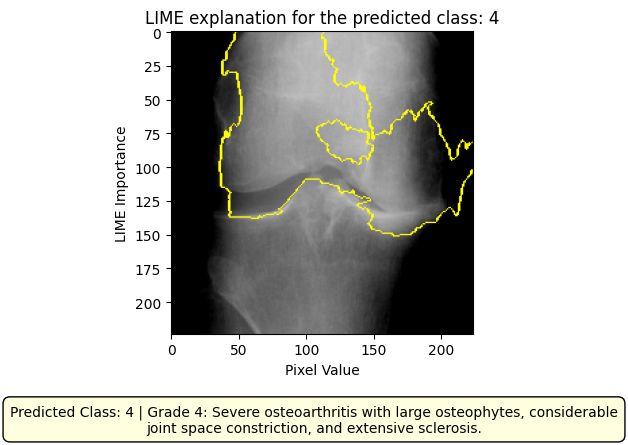

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
import tensorflow as tf
from tensorflow.keras.applications.xception import preprocess_input
from skimage.segmentation import mark_boundaries

# Load your model
model = tf.keras.models.load_model('/content/xception_model (1).h5', compile=False)

# Load and preprocess the image
def load_image(image_path):
    from tensorflow.keras.preprocessing import image
    original_img = image.load_img(image_path, target_size=(224, 224))
    input_img = image.img_to_array(original_img)
    return original_img, input_img

# Path to your image
image_path = '/content/grade-4.png'  # Replace with the actual path to your image
original_img, input_img = load_image(image_path)

# Preprocess the image for the Xception model
input_img_preprocessed = preprocess_input(np.expand_dims(input_img, axis=0))

# Define grade descriptions
grade_descriptions = {
    0: "Grade 0: A healthy knee joint with no symptoms of osteoarthritis.",
    1: "Grade 1: Early symptoms of osteoarthritis with probable narrowing of the joint space and osteophytic lipping.",
    2: "Grade 2: Clear presence of osteophytes and potential joint space constriction.",
    3: "Grade 3: Moderate osteoarthritis with many osteophytes, joint space constriction, and mild sclerosis.",
    4: "Grade 4: Severe osteoarthritis with large osteophytes, considerable joint space constriction, and extensive sclerosis."
}

# Predict the class
predictions = model.predict(input_img_preprocessed)
predicted_class = np.argmax(predictions[0])
confidence = predictions[0][predicted_class]

# Print the grade description and confidence level for the predicted class
print(f"Predicted Class: {predicted_class}, {grade_descriptions[predicted_class]} with confidence level of {confidence:.2f}")

# Explain the model's predictions using LIME
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(input_img, model.predict, top_labels=5, hide_color=0, num_samples=1000)

# Get the LIME explanation for the predicted class
lime_image, mask = explanation.get_image_and_mask(predicted_class, positive_only=True, num_features=5, hide_rest=False)

# Display the LIME explanation
plt.figure()
plt.imshow(mark_boundaries(lime_image, mask))
plt.title(f"LIME explanation for the predicted class: {predicted_class}")
plt.xlabel("Pixel Value")
plt.ylabel("LIME Importance")

# Adjust layout to leave space for text
plt.subplots_adjust(bottom=0.25)

# Add text annotation below the image
description_text = f"Predicted Class: {predicted_class} | {grade_descriptions[predicted_class]}"
plt.figtext(0.5, 0.05, description_text, wrap=True, horizontalalignment='center', fontsize=10, color='black',
            bbox=dict(facecolor='lightyellow', edgecolor='black', boxstyle='round,pad=0.5'))

plt.show()
